# Hospital Segmentation Study

**Project objective:** Segment patients based on healthcare utilization behaviour, visit frequency, recency and billing value. Use RFM scoring and K-Means clustering, compare the results, profile each segment and suggest suitable actions.

> Before running: keep `anonymized_data.csv` in the same folder as this notebook, or update the file path in the next cell. Run the notebook from top to bottom so that outputs come from one consistent execution.

## 1. Import required libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

import os
os.makedirs('images', exist_ok=True)

def save_show(name):
    # Save the chart as an image (used in the report and PPT), then show it
    plt.savefig(f'images/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

## 2. Load the dataset

In [6]:
# Load the dataset
file_path = "anonymized_data.csv"
df = pd.read_csv(file_path, low_memory=False)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (538544, 39)


,source_year,source_month,source_sheet,load_order,no,patient_id,visit_date,discharge_date,age,gender,age_source,age_conflict,diagnosis_text,icd10,g_drg,drugs_amount,investigation_amount,outpatient_amount,inpatient_amount,service_amount,total_claim,has_critical_missing,age_at_visit,icd10_codes,icd10_chapter,icd10_chapters,diagnosis_clean,disease_category,disease_categories_all,target_disease_fine,target_disease_coarse,total_visits,visits_this_year,visit_number,days_since_last_visit,days_to_next_visit,revisit_30,revisit_90,revisit_180
0,2021,AUGUST,ClaimData,62,13.0,312725a82128217f,2021-08-01,2021-08-01 00:00:00,72.00,M,computed_from_dob,False,Unknown,N34.1,OPDC06A,4.02,0.0,0.0,0.0,12.24,0.0,False,72.00,N34.1,N,"['N', '3', '4', '.', '1']",unknown,GENITOURINARY_SYSTEM_DISORDERS,['GENITOURINARY_SYSTEM_DISORDERS'],N34.1,GENITOURINARY_SYSTEM_DISORDERS,1.00,1.00,1.00,NaN,NaN,False,False,False
1,2020,November,ClaimData,59,868.0,f152bdaaf63a4104,2020-11-14,2020-11-14 00:00:00,60.00,F,computed_from_dob,False,Other spondylosis,M47.8,OPDC06A,0.0,0.0,0.0,0.0,12.24,0.0,False,60.00,M47.8,M,"['M', '4', '7', '.', '8']",other spondylosis,SPONDYLOSIS,['MUSCULOSKELETAL_AND_CONNECTIVE_DISORDERS'],M47.8,SPONDYLOSIS,1.00,1.00,1.00,NaN,NaN,False,False,False
2,2020,November,ClaimData,59,202.0,bd77ccca47ca8af7,2020-11-04,2020-11-04 00:00:00,60.00,F,computed_from_dob,False,Essential (primary) hypertension,I10,OPDC06A,29.4,0.0,0.0,0.0,12.24,0.0,False,60.00,I10,I,"['I', '1', '0']",essential primary hypertension,HYPERTENSION,['CIRCULATORY_SYSTEM_DISORDERS'],I10,HYPERTENSION,1.00,1.00,1.00,NaN,NaN,False,False,False
3,2022,MAY,ClaimData,74,791.0,6bdc604f6d5d4d74,2022-05-17,2022-05-17 00:00:00,23.00,M,computed_from_dob,False,"Myalgia,Salmonella enteritis","M79.1,A02.0",OPDC06A,0.94,0.0,0.0,0.0,12.24,0.0,False,23.00,"M79.1,A02.0",M,"['M', '7', '9', '.', '1', ',', 'A', '0', '2', ...","myalgia,salmonella enteritis",ENTERITIS,"['INFECTIOUS_AND_PARASITIC', 'MUSCULOSKELETAL_...","M79.1,A02.0",ENTERITIS,1.00,1.00,1.00,NaN,NaN,False,False,False
4,2022,APRIL,ClaimData,71,613.0,e6c1177652a56955,2022-04-17,2022-04-17 00:00:00,32.00,M,computed_from_dob,False,Unknown,"N39,M79.1",OPDC06A,1.96,0.0,0.0,0.0,12.24,0.0,False,32.00,"N39,M79.1",N,"['N', '3', '9', ',', 'M', '7', '9', '.', '1']",unknown,GENITOURINARY_SYSTEM_DISORDERS,"['MUSCULOSKELETAL_AND_CONNECTIVE_DISORDERS', '...","N39,M79.1",GENITOURINARY_SYSTEM_DISORDERS,1.00,1.00,1.00,NaN,NaN,False,False,False


## 3. Understand the dataset

In [8]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\\nColumn names:")
print(df.columns.tolist())

print("\\nDataset information:")
df.info()

Number of rows: 538544
Number of columns: 39
\nColumn names:
['source_year', 'source_month', 'source_sheet', 'load_order', 'no', 'patient_id', 'visit_date', 'discharge_date', 'age', 'gender', 'age_source', 'age_conflict', 'diagnosis_text', 'icd10', 'g_drg', 'drugs_amount', 'investigation_amount', 'outpatient_amount', 'inpatient_amount', 'service_amount', 'total_claim', 'has_critical_missing', 'age_at_visit', 'icd10_codes', 'icd10_chapter', 'icd10_chapters', 'diagnosis_clean', 'disease_category', 'disease_categories_all', 'target_disease_fine', 'target_disease_coarse', 'total_visits', 'visits_this_year', 'visit_number', 'days_since_last_visit', 'days_to_next_visit', 'revisit_30', 'revisit_90', 'revisit_180']
\nDataset information:
<class 'pandas.DataFrame'>
RangeIndex: 538544 entries, 0 to 538543
Data columns (total 39 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   source_year             538544 non-null  int64 

In [9]:
# Check missing values
missing_values = df.isnull().sum().sort_values(ascending=False)
missing_values[missing_values > 0]

days_to_next_visit        426985
days_since_last_visit     426985
discharge_date            424885
icd10                     417565
target_disease_fine       417565
g_drg                     415600
visit_number              355163
visit_date                348083
age_at_visit              336919
age                       336919
patient_id                335855
visits_this_year          335855
total_visits              335855
icd10_codes               300973
no                        175848
inpatient_amount          121993
total_claim               121993
service_amount            121993
outpatient_amount         121993
investigation_amount      121993
drugs_amount              121993
disease_categories_all    116804
icd10_chapter             116600
diagnosis_clean                1
dtype: int64

In [10]:
# Check duplicate rows before removing them
duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)

Duplicate rows: 179276


## 4. Data cleaning

The patient identifier and visit date are required for patient-level analysis. Duplicate rows are removed. Billing fields are converted to numeric values. Missing billing values are filled with zero **as an explicit assumption**; if a blank amount means unknown rather than no charge in the source data, do not use this assumption.

In [12]:
# Work on a copy of the loaded data
df = df.copy()

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Convert date columns
df['visit_date'] = pd.to_datetime(df['visit_date'], errors='coerce')
df['discharge_date'] = pd.to_datetime(df['discharge_date'], errors='coerce')

# Remove rows without essential patient information
df = df.dropna(subset=['patient_id', 'visit_date']).copy()

# Convert billing columns to numeric values
billing_columns = [
    'drugs_amount',
    'investigation_amount',
    'outpatient_amount',
    'inpatient_amount',
    'service_amount',
    'total_claim'
]

for col in billing_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Assumption: missing billing amounts represent zero recorded amount
df[billing_columns] = df[billing_columns].fillna(0)

# Keep diagnosis text usable for later inspection
if 'diagnosis_text' in df.columns:
    df['diagnosis_text'] = df['diagnosis_text'].fillna('Unknown')

print("Shape after cleaning:", df.shape)
print("Remaining missing values in essential fields:")
print(df[['patient_id', 'visit_date', 'total_claim']].isnull().sum())

Shape after cleaning: (183381, 39)
Remaining missing values in essential fields:
patient_id     0
visit_date     0
total_claim    0
dtype: int64


## 5. Create date-related features

In [14]:
# Calculate length of stay from visit and discharge dates
df['length_of_stay'] = (
    df['discharge_date'] - df['visit_date']
).dt.days

# Negative stay values are not meaningful for this calculation
df['length_of_stay'] = df['length_of_stay'].clip(lower=0)

# Extract month and year
df['month'] = df['visit_date'].dt.month
df['year'] = df['visit_date'].dt.year

df[['patient_id', 'visit_date', 'total_claim',
    'length_of_stay', 'month', 'year']].head()

,patient_id,visit_date,total_claim,length_of_stay,month,year
0,312725a82128217f,2021-08-01,0.00,0.00,8,2021
1,f152bdaaf63a4104,2020-11-14,0.00,0.00,11,2020
2,bd77ccca47ca8af7,2020-11-04,0.00,0.00,11,2020
3,6bdc604f6d5d4d74,2022-05-17,0.00,0.00,5,2022
4,e6c1177652a56955,2022-04-17,0.00,0.00,4,2022


## 6. Create patient-level behavioural features

In [16]:
# Use the day after the last recorded visit as the reference date
reference_date = df['visit_date'].max() + pd.Timedelta(days=1)

patient_data = df.groupby('patient_id').agg(
    frequency=('visit_date', 'count'),
    last_visit=('visit_date', 'max'),
    monetary=('total_claim', 'sum'),
    average_bill=('total_claim', 'mean'),
    average_stay=('length_of_stay', 'mean')
).reset_index()

# Recency is the number of days since the patient's last visit
patient_data['recency'] = (
    reference_date - patient_data['last_visit']
).dt.days

# Add a patient-level 30-day revisit indicator when available
if 'revisit_30' in df.columns:
    readmission = df.groupby('patient_id')['revisit_30'].max()
    patient_data['readmission_30'] = (
        patient_data['patient_id'].map(readmission).fillna(False).astype(int)
    )
else:
    patient_data['readmission_30'] = 0

patient_data.head()

,patient_id,frequency,last_visit,monetary,average_bill,average_stay,recency,readmission_30
0,0000385f21afaf45,1,2021-06-13,0.00,0.00,0.00,1541,0
1,000078299e35de5f,1,2024-03-07,19.78,19.78,0.00,543,0
2,0000a10aca4e36d8,1,2019-08-01,0.00,0.00,0.00,2223,0
3,0000af8148211b10,2,2024-10-30,38.88,19.44,0.00,306,0
4,0001137d97fa31da,2,2015-10-25,47.12,23.56,NaN,3599,0


## 7. Monthly visit trend and seasonality

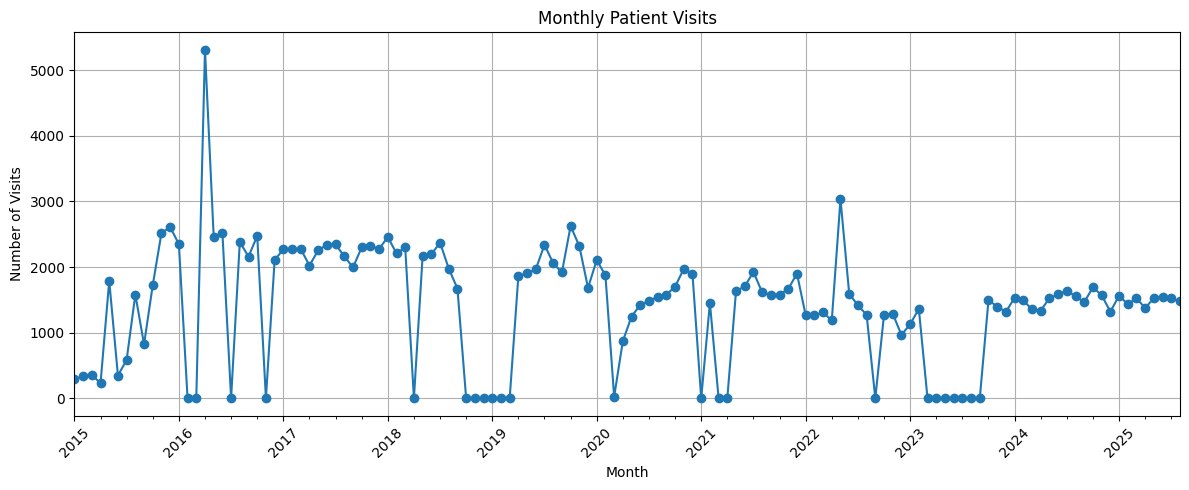

In [18]:
# Monthly trend keeps the year and month together
monthly_visits = (
    df.set_index('visit_date')
      .resample('MS')
      .size()
)

monthly_visits.plot(figsize=(12, 5), marker='o')
plt.title("Monthly Patient Visits")
plt.xlabel("Month")
plt.ylabel("Number of Visits")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
save_show('monthly_visits')

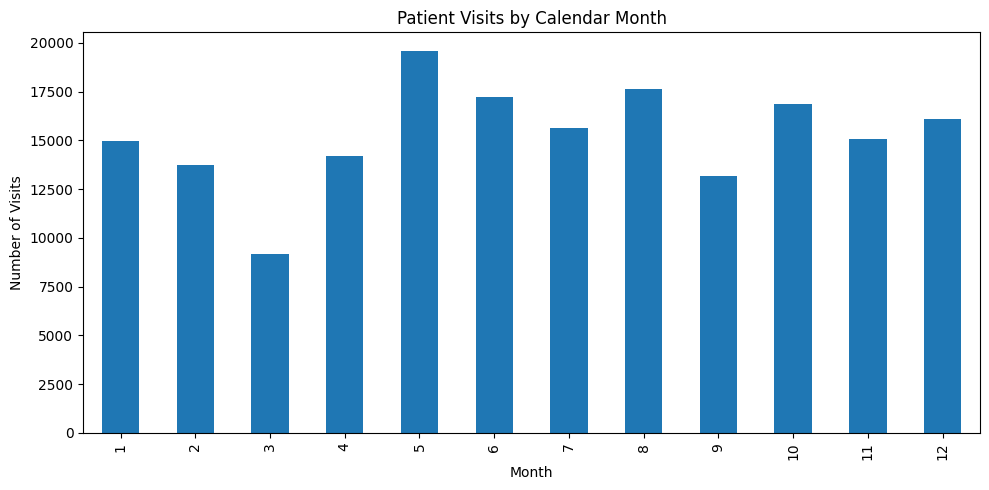

In [20]:
# Compare visit counts by calendar month across all years
monthly_pattern = df.groupby('month').size()

monthly_pattern.plot(kind='bar', figsize=(10, 5))
plt.title("Patient Visits by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Number of Visits")
plt.tight_layout()
save_show('visits_by_calendar_month')

## 8. Explore patient behaviour and outliers

In [24]:
patient_data[['frequency', 'recency', 'monetary']].describe()

,frequency,recency,monetary
count,"71,817.00","71,817.00","71,817.00"
mean,2.55,"1,880.29",40.13
std,3.18,"1,094.08",128.50
min,1.00,1.00,0.00
25%,1.00,"1,111.00",0.00
50%,1.00,"1,876.00",14.68
75%,3.00,"2,810.00",35.15
max,104.00,"3,892.00","3,442.00"


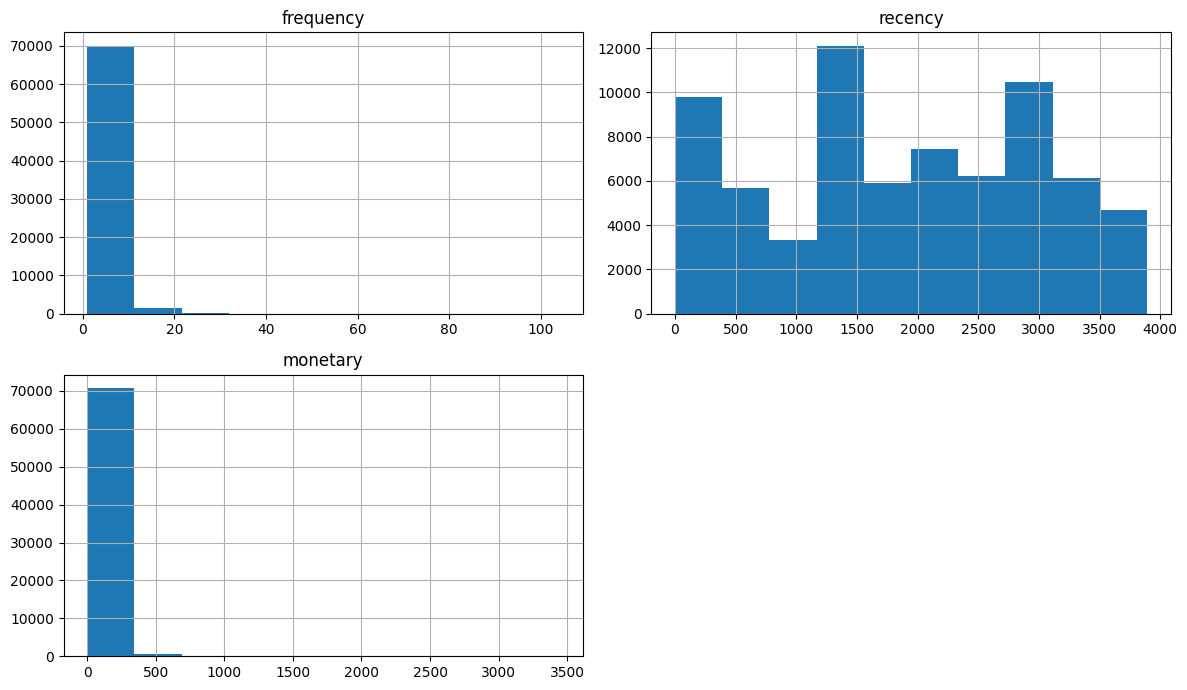

In [25]:
patient_data[['frequency', 'recency', 'monetary']].hist(figsize=(12, 7))
plt.tight_layout()
save_show('rfm_histograms')

In [26]:
print("Skewness:")
print(patient_data[['frequency', 'recency', 'monetary']].skew())

Skewness:
frequency    5.07
recency     -0.11
monetary    10.83
dtype: float64


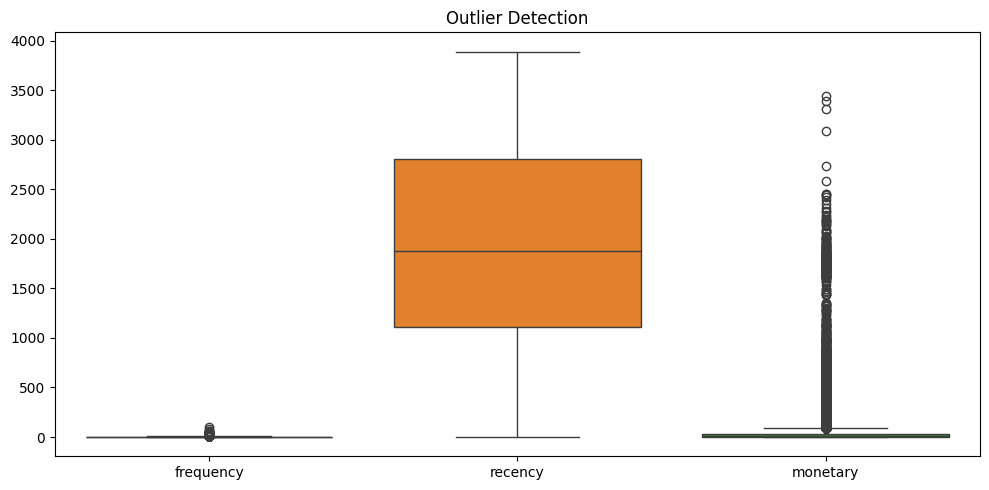

In [27]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=patient_data[['frequency', 'recency', 'monetary']])
plt.title("Outlier Detection")
plt.tight_layout()
save_show('outlier_boxplot')

## 9. RFM segmentation

- **Recency:** How recently the patient visited. A lower number of days is better.
- **Frequency:** How often the patient visited.
- **Monetary:** The total recorded billing amount for the patient.

The rank is used before `qcut` so that tied values do not prevent the quartile calculation.

In [30]:
# RFM scores: higher score means a more favourable value
patient_data['R_score'] = pd.qcut(
    patient_data['recency'].rank(method='first'),
    4,
    labels=[4, 3, 2, 1]
).astype(int)

patient_data['F_score'] = pd.qcut(
    patient_data['frequency'].rank(method='first'),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

patient_data['M_score'] = pd.qcut(
    patient_data['monetary'].rank(method='first'),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

patient_data['RFM_score'] = (
    patient_data['R_score'] +
    patient_data['F_score'] +
    patient_data['M_score']
)

patient_data[['patient_id', 'R_score', 'F_score',
              'M_score', 'RFM_score']].head()

,patient_id,R_score,F_score,M_score,RFM_score
0,0000385f21afaf45,3,1,1,5
1,000078299e35de5f,4,1,3,8
2,0000a10aca4e36d8,2,1,1,4
3,0000af8148211b10,4,3,4,11
4,0001137d97fa31da,1,3,4,8


In [31]:
# Create simple rule-based RFM groups
def rfm_segment(score):
    if score >= 10:
        return 'High RFM'
    elif score >= 7:
        return 'Regular RFM'
    elif score >= 5:
        return 'Occasional RFM'
    else:
        return 'Low RFM'

patient_data['RFM_segment'] = patient_data['RFM_score'].apply(rfm_segment)

patient_data['RFM_segment'].value_counts()

RFM_segment
Regular RFM       32045
Occasional RFM    20813
High RFM          13240
Low RFM            5719
Name: count, dtype: int64

## 10. K-Means clustering

In [33]:
# Select behavioural features for clustering
cluster_columns = ['frequency', 'recency', 'monetary', 'average_bill']

features = patient_data[cluster_columns].copy()

# Reduce right-skewness while retaining zero values
features = np.log1p(features.clip(lower=0))

# Standardize the features so they are on a comparable scale
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

print("Clustering data shape:", scaled_features.shape)

Clustering data shape: (71817, 4)


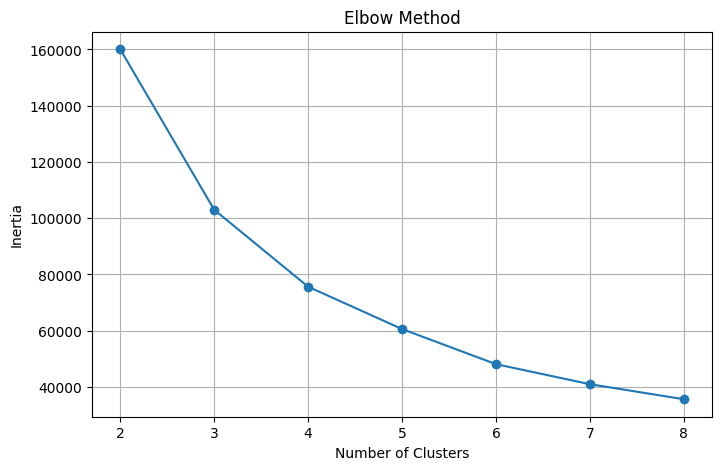

In [34]:
# Elbow method
inertia = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(scaled_features)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 9), inertia, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(range(2, 9))
plt.grid(True)
save_show('elbow_method')

In [35]:
# Silhouette scores; sample_size makes this practical for a large dataset
silhouette_results = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(scaled_features)

    score = silhouette_score(
        scaled_features,
        labels,
        sample_size=min(5000, len(scaled_features)),
        random_state=42
    )

    silhouette_results.append((k, score))
    print("Clusters:", k, "Silhouette Score:", round(score, 3))

Clusters: 2 Silhouette Score: 0.492
Clusters: 3 Silhouette Score: 0.52
Clusters: 4 Silhouette Score: 0.544
Clusters: 5 Silhouette Score: 0.541
Clusters: 6 Silhouette Score: 0.539
Clusters: 7 Silhouette Score: 0.508
Clusters: 8 Silhouette Score: 0.508


Clusters: 4 Silhouette Score: 0.544


Clusters: 5 Silhouette Score: 0.541


Clusters: 6 Silhouette Score: 0.539


Clusters: 7 Silhouette Score: 0.508


Clusters: 8 Silhouette Score: 0.508


In [36]:
# Select four clusters for the initial business analysis.
# Review the elbow plot, silhouette scores and segment profiles before finalizing.
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

patient_data['KMeans_segment'] = kmeans.fit_predict(scaled_features)

patient_data[['patient_id', 'KMeans_segment']].head()

,patient_id,KMeans_segment
0,0000385f21afaf45,1
1,000078299e35de5f,3
2,0000a10aca4e36d8,1
3,0000af8148211b10,3
4,0001137d97fa31da,0


## 11. Segment profiling

In [38]:
profile = patient_data.groupby('KMeans_segment').agg(
    patient_count=('patient_id', 'count'),
    average_frequency=('frequency', 'mean'),
    average_recency=('recency', 'mean'),
    average_billing=('monetary', 'mean'),
    total_revenue=('monetary', 'sum'),
    average_stay=('average_stay', 'mean'),
    readmission_rate=('readmission_30', 'mean')
).reset_index()

profile['patient_share'] = (
    profile['patient_count'] / profile['patient_count'].sum()
) * 100

total_revenue = profile['total_revenue'].sum()

if total_revenue != 0:
    profile['revenue_share'] = (
        profile['total_revenue'] / total_revenue
    ) * 100
else:
    profile['revenue_share'] = 0

profile['readmission_rate'] = profile['readmission_rate'] * 100

profile.round(2)

,KMeans_segment,patient_count,average_frequency,average_recency,average_billing,total_revenue,average_stay,readmission_rate,patient_share,revenue_share
0,0,27546,1.56,"2,877.27",28.98,"798,326.15",0.02,21.05,38.36,27.70
1,1,24688,2.15,"1,668.13",0.00,55.28,0.04,28.70,34.38,0.00
2,2,7115,8.99,"1,484.41",221.68,"1,577,246.42",0.02,87.18,9.91,54.73
3,3,12468,1.87,323.63,40.62,"506,456.21",0.00,32.07,17.36,17.57


### Interpret the clusters before naming them

Cluster numbers are arbitrary; cluster 0 is not automatically a particular patient type. Use the profile table to decide the labels. A cluster with lower recency has more recent visits; a cluster with higher frequency has more visits; and higher monetary value means higher recorded billing.

In [42]:
# Inspect segment profiles in order of frequency
profile.sort_values('average_frequency', ascending=False).round(2)

,KMeans_segment,patient_count,average_frequency,average_recency,average_billing,total_revenue,average_stay,readmission_rate,patient_share,revenue_share
2,2,7115,8.99,"1,484.41",221.68,"1,577,246.42",0.02,87.18,9.91,54.73
1,1,24688,2.15,"1,668.13",0.00,55.28,0.04,28.70,34.38,0.00
3,3,12468,1.87,323.63,40.62,"506,456.21",0.00,32.07,17.36,17.57
0,0,27546,1.56,"2,877.27",28.98,"798,326.15",0.02,21.05,38.36,27.70


### 11b. Name the segments

In [45]:
# Give every cluster a business-friendly name using the profile values.
# (Cluster numbers are arbitrary, so the names are decided by rules, not by number.)
remaining = profile.set_index('KMeans_segment')
segment_names = {}

top = remaining['average_frequency'].idxmax()            # visits most often
segment_names[top] = 'Frequent High-Value Patients'
remaining = remaining.drop(top)

zero = remaining['average_billing'].idxmin()             # lowest recorded billing
segment_names[zero] = 'Zero-Billing Patients'
remaining = remaining.drop(zero)

recent = remaining['average_recency'].idxmin()           # visited most recently
segment_names[recent] = 'Recent Regular Patients'
remaining = remaining.drop(recent)

segment_names[remaining.index[0]] = 'Lapsed One-Time Patients'   # long ago, few visits

profile['segment_name'] = profile['KMeans_segment'].map(segment_names)
patient_data['segment_name'] = patient_data['KMeans_segment'].map(segment_names)

profile[['KMeans_segment', 'segment_name', 'patient_count', 'patient_share',
         'average_frequency', 'average_recency', 'average_billing',
         'revenue_share', 'readmission_rate']].round(2).sort_values('revenue_share', ascending=False)

,KMeans_segment,segment_name,patient_count,patient_share,average_frequency,average_recency,average_billing,revenue_share,readmission_rate
2,2,Frequent High-Value Patients,7115,9.91,8.99,"1,484.41",221.68,54.73,87.18
0,0,Lapsed One-Time Patients,27546,38.36,1.56,"2,877.27",28.98,27.70,21.05
3,3,Recent Regular Patients,12468,17.36,1.87,323.63,40.62,17.57,32.07
1,1,Zero-Billing Patients,24688,34.38,2.15,"1,668.13",0.00,0.00,28.70


## 12. Compare RFM and K-Means

In [48]:
comparison = pd.crosstab(
    patient_data['RFM_segment'],
    patient_data['KMeans_segment']
)

print("RFM vs K-Means comparison:")
comparison

RFM vs K-Means comparison:


KMeans_segment,0,1,2,3
RFM_segment,,,,
High RFM,1305,28,5424,6483
Low RFM,3179,2540,0,0
Occasional RFM,11005,9808,0,0
Regular RFM,12057,12312,1691,5985


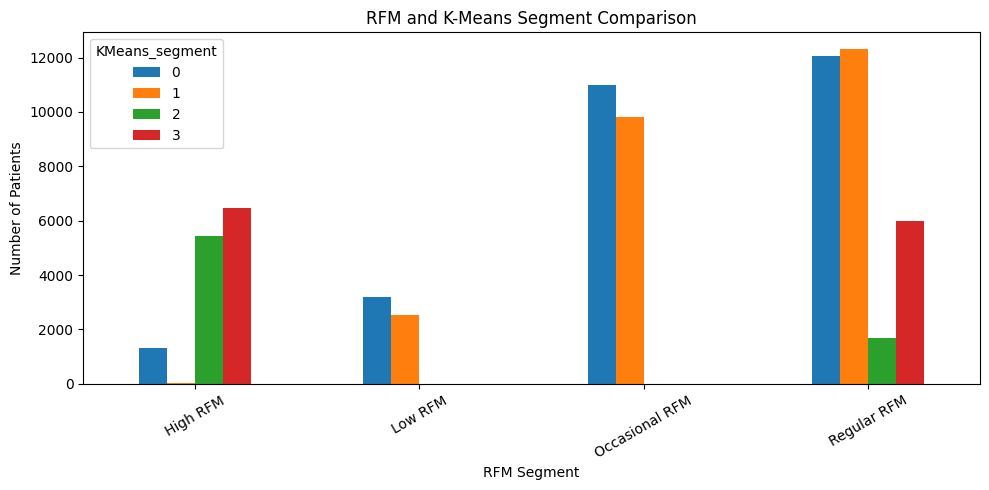

In [51]:
comparison.plot(kind='bar', figsize=(10, 5))
plt.title("RFM and K-Means Segment Comparison")
plt.xlabel("RFM Segment")
plt.ylabel("Number of Patients")
plt.xticks(rotation=30)
plt.tight_layout()
save_show('rfm_vs_kmeans')

## 13. Business recommendations

In [53]:
# Recommendations with a simple cost-benefit estimate.
# IMPORTANT: the rates and costs below are ASSUMPTIONS (change them if you have better numbers).
# Money is in the same currency unit as the billing columns of the dataset.

# Average bill per visit for each segment (taken from the data)
seg = patient_data.groupby('segment_name').agg(
    patients=('patient_id', 'count'),
    visits=('frequency', 'sum'),
    revenue=('monetary', 'sum')
)
seg['avg_bill_per_visit'] = seg['revenue'] / seg['visits']

# Assumptions: cost per patient contacted, and share of patients who make one extra visit
assumptions = {
    'Frequent High-Value Patients': {'cost_per_patient': 2.00, 'response_rate': 0.10},   # follow-up call / care coordinator
    'Lapsed One-Time Patients':     {'cost_per_patient': 0.10, 'response_rate': 0.03},   # SMS / call reminder
    'Recent Regular Patients':      {'cost_per_patient': 0.20, 'response_rate': 0.05},   # preventive check-up reminder
}

actions = {
    'Frequent High-Value Patients': ('Care-coordination: follow-up call after each visit and a regular health review',
                                     'Cut 30-day revisit rate by 5 percentage points; follow-up completion at least 80%'),
    'Lapsed One-Time Patients':     ('Send SMS / call reminders for check-ups to patients who have not visited for years',
                                     'At least 3% of reminded patients book a visit within 90 days'),
    'Recent Regular Patients':      ('Offer preventive-care / health check-up packages and reminders',
                                     'Preventive appointment attendance up by 5% in 6 months'),
    'Zero-Billing Patients':        ('Check why these visits show a zero claim (free / exempt services or billing not entered) with the hospital billing team',
                                     'Reason for zero claims confirmed for at least 90% of these patients; unexplained zero-claim visits halved'),
}

rows = []
for name, (action, target) in actions.items():
    n = seg.loc[name, 'patients']
    if name in assumptions:
        a = assumptions[name]
        cost = n * a['cost_per_patient']
        benefit = n * a['response_rate'] * seg.loc[name, 'avg_bill_per_visit']
        net = benefit - cost
    else:
        cost, benefit, net = 1000.0, np.nan, np.nan      # fixed audit cost (assumption); benefit not estimated
    rows.append([name, int(n), action, round(cost, 0), round(benefit, 0) if benefit == benefit else 'Not estimated',
                 round(net, 0) if net == net else 'Not estimated', target])

recommendations = pd.DataFrame(rows, columns=[
    'Segment', 'Patients', 'Suggested action', 'Estimated cost',
    'Estimated benefit', 'Net benefit', 'Measurable target'])
pd.set_option('display.max_colwidth', 80)
recommendations

,Segment,Patients,Suggested action,Estimated cost,Estimated benefit,Net benefit,Measurable target
0,Frequent High-Value Patients,7115,Care-coordination: follow-up call after each visit and a regular health review,"14,230.00","17,553.00","3,323.00",Cut 30-day revisit rate by 5 percentage points; follow-up completion at leas...
1,Lapsed One-Time Patients,27546,Send SMS / call reminders for check-ups to patients who have not visited for...,"2,755.00","15,337.00","12,582.00",At least 3% of reminded patients book a visit within 90 days
2,Recent Regular Patients,12468,Offer preventive-care / health check-up packages and reminders,"2,494.00","13,543.00","11,050.00",Preventive appointment attendance up by 5% in 6 months
3,Zero-Billing Patients,24688,Check why these visits show a zero claim (free / exempt services or billing ...,"1,000.00",Not estimated,Not estimated,Reason for zero claims confirmed for at least 90% of these patients; unexpla...


**How the estimate works:** `Estimated cost` = patients x cost per patient. `Estimated benefit` = patients x share who make one extra visit x average bill per visit of that segment.
All costs and response rates are **assumptions**, not measured results. For the Zero-Billing segment no benefit is claimed. All of their visits have a recorded claim of 0, so the first step is to find out whether these are free / exempt services or billing that was never entered.

## 13b. Success check
The task says success means: (1) segments are clearly different on at least three KPIs, (2) no segment is smaller than 5% of the patients, and (3) each action has a measurable target.

In [56]:
# (1) Segments differ on at least 3 KPIs  (spread = (max - min) / mean across the 4 segments)
kpis = ['average_frequency', 'average_recency', 'average_billing', 'readmission_rate']
check = pd.DataFrame({
    'min': profile[kpis].min(),
    'max': profile[kpis].max(),
    'spread': (profile[kpis].max() - profile[kpis].min()) / profile[kpis].mean()
})
check['clearly_different'] = check['spread'] >= 0.30
print(check.round(2))
print("\nKPIs that clearly differ:", int(check['clearly_different'].sum()), "(need at least 3)")

# (2) No segment smaller than 5% of the patients
smallest = profile['patient_share'].min()
print("\nSmallest segment share: {:.1f}%  -> {}".format(smallest, "PASS" if smallest >= 5 else "FAIL"))

# (3) Every action has a measurable target
print("Actions with a measurable target:", recommendations['Measurable target'].notna().sum(),
      "of", len(recommendations))

                     min      max  spread  clearly_different
average_frequency   1.56     8.99    2.04               True
average_recency   323.63 2,877.27    1.61               True
average_billing     0.00   221.68    3.04               True
readmission_rate   21.05    87.18    1.57               True

KPIs that clearly differ: 4 (need at least 3)

Smallest segment share: 9.9%  -> PASS
Actions with a measurable target: 4 of 4


## 13c. Why K-Means with 4 segments (final choice)
**Alternative compared:** the rule-based RFM groups (High / Regular / Occasional / Low).

- RFM only uses simple score cut-offs. The comparison table shows that one RFM group can mix very different patients (for example "Regular RFM" is spread across all four K-Means segments).
- K-Means uses the real values of frequency, recency and billing, so it finds a small group of very frequent, high-billing patients that RFM cannot separate clearly.
- Number of segments: K = 4 has the best silhouette score. K = 5 is almost the same, so the simpler K = 4 is chosen; every segment is also large enough (above 5%) to act on.

So K-Means with 4 segments is the final segmentation. RFM is kept as a simple reference.

In [60]:
# Numbers that support the choice
sil_table = pd.DataFrame(silhouette_results, columns=['k', 'silhouette_score']).round(3)
print(sil_table.to_string(index=False, float_format=lambda x: f'{x:.3f}'))
print("\nBest k by silhouette score:", int(sil_table.loc[sil_table['silhouette_score'].idxmax(), 'k']))

# How different are the two methods? (0 = unrelated groupings, 1 = identical groupings)
from sklearn.metrics import adjusted_rand_score
rfm_codes = patient_data['RFM_segment'].astype('category').cat.codes
print("Agreement between RFM groups and K-Means groups (adjusted Rand index):",
      round(adjusted_rand_score(rfm_codes, patient_data['KMeans_segment']), 3))

 k  silhouette_score
 2             0.492
 3             0.520
 4             0.544
 5             0.541
 6             0.539
 7             0.508
 8             0.508

Best k by silhouette score: 4
Agreement between RFM groups and K-Means groups (adjusted Rand index): 0.12


## 14. Segment stability and migration

In [62]:
# Split the visit data into two time periods
first_period = df[df['visit_date'].dt.year <= 2022].copy()
second_period = df[df['visit_date'].dt.year > 2022].copy()

print("First period records:", len(first_period))
print("Second period records:", len(second_period))

First period records: 146606
Second period records: 36775


In [63]:
def create_period_features(data):
    result = data.groupby('patient_id').agg(
        frequency=('visit_date', 'count'),
        monetary=('total_claim', 'sum'),
        last_visit=('visit_date', 'max')
    ).reset_index()

    period_reference_date = data['visit_date'].max() + pd.Timedelta(days=1)

    result['recency'] = (
        period_reference_date - result['last_visit']
    ).dt.days

    result['average_bill'] = (
        result['monetary'] / result['frequency']
    )

    return result

first_data = create_period_features(first_period)
second_data = create_period_features(second_period)

print("Patients in first period:", len(first_data))
print("Patients in second period:", len(second_data))

Patients in first period: 59798
Patients in second period: 16493


In [67]:
# Fit the scaler and clustering model on the first period
stability_features = ['frequency', 'recency', 'monetary', 'average_bill']

X_first = np.log1p(
    first_data[stability_features].clip(lower=0)
)
X_second = np.log1p(
    second_data[stability_features].clip(lower=0)
)

stability_scaler = StandardScaler()
X_first_scaled = stability_scaler.fit_transform(X_first)
X_second_scaled = stability_scaler.transform(X_second)

stability_model = KMeans(n_clusters=4, random_state=42, n_init=10)

first_data['segment_first'] = stability_model.fit_predict(X_first_scaled)
second_data['segment_second'] = stability_model.predict(X_second_scaled)

print("Period segmentation completed.")

Period segmentation completed.


In [69]:
# Compare only patients who appear in both periods
migration = first_data[
    ['patient_id', 'segment_first']
].merge(
    second_data[['patient_id', 'segment_second']],
    on='patient_id',
    how='inner'
)

print("Patients present in both periods:", len(migration))

migration_table = pd.crosstab(
    migration['segment_first'],
    migration['segment_second']
)

migration_table

Patients present in both periods: 4474


segment_second,0,1,2,3
segment_first,,,,
0,95,39,157,186
1,64,71,325,385
2,111,118,635,648
3,194,122,335,989


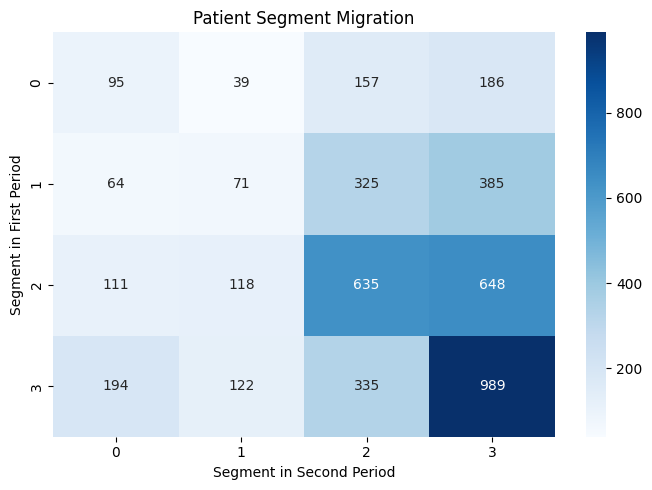

In [70]:
plt.figure(figsize=(7, 5))
sns.heatmap(migration_table, annot=True, fmt='d', cmap='Blues')
plt.title("Patient Segment Migration")
plt.xlabel("Segment in Second Period")
plt.ylabel("Segment in First Period")
plt.tight_layout()
save_show('segment_migration_heatmap')

**Stability interpretation:** The migration table counts patients assigned to each cluster in the first period and the second period. Cluster IDs can change meaning when a model is refitted, so this notebook applies the first-period model to the second period. This makes the cluster labels comparable, although it does not mean that patient behaviour is unchanged.

In [72]:
# How many patients stayed in the same segment in both periods?
same_segment = (migration['segment_first'] == migration['segment_second'])
print("Patients present in both periods:", len(migration))
print("Stayed in the same segment: {} ({:.1f}%)".format(same_segment.sum(), same_segment.mean() * 100))
print("Moved to a different segment: {:.1f}%".format((1 - same_segment.mean()) * 100))

Patients present in both periods: 4474
Stayed in the same segment: 1790 (40.0%)
Moved to a different segment: 60.0%


**Reading the stability result:** only patients who visited in *both* periods can be compared, and they are a small part of all patients. The share who stay in the same segment shows how stable the segments are: the lower it is, the more patient behaviour changes over time, so the segments should be refreshed regularly. The segment numbers in this section belong to the first-period model, so they are not the same as the named segments above.

## 15. Final visualizations

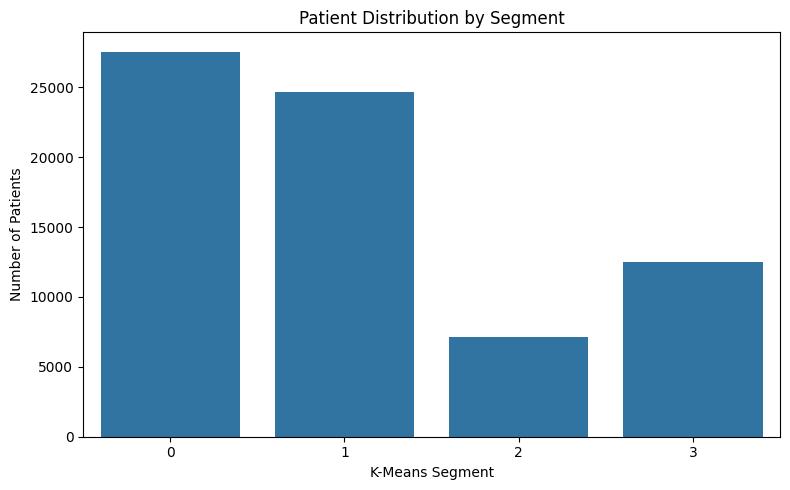

In [75]:
# Patient distribution by K-Means segment
plt.figure(figsize=(8, 5))
sns.countplot(data=patient_data, x='KMeans_segment')
plt.title("Patient Distribution by Segment")
plt.xlabel("K-Means Segment")
plt.ylabel("Number of Patients")
plt.tight_layout()
save_show('patient_distribution')

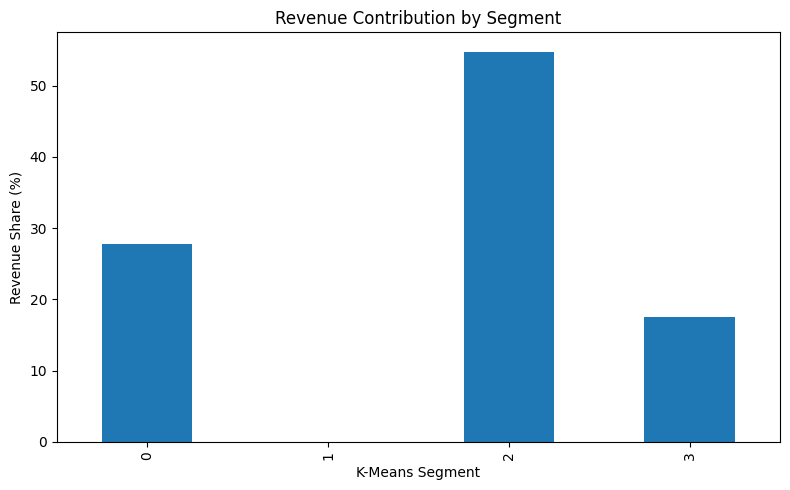

In [76]:
# Revenue contribution by segment
profile.plot(
    x='KMeans_segment',
    y='revenue_share',
    kind='bar',
    legend=False,
    figsize=(8, 5)
)
plt.title("Revenue Contribution by Segment")
plt.xlabel("K-Means Segment")
plt.ylabel("Revenue Share (%)")
plt.tight_layout()
save_show('revenue_contribution')

## 16. Export results

In [78]:
# Save patient-level segments and segment profile
patient_data.to_csv("patient_segments.csv", index=False)
profile.to_csv("segment_profile.csv", index=False)
comparison.to_csv("rfm_kmeans_comparison.csv")
migration_table.to_csv("segment_migration.csv")

print("Files exported successfully!")
# Also save the named profile and the recommendations
profile.to_csv("segment_profile_named.csv", index=False)
recommendations.to_csv("segment_recommendations.csv", index=False)

Files exported successfully!


## 17. Conclusion

Patients were segmented using recency, frequency and billing value. RFM scoring gives a simple rule-based view, and K-Means (4 segments) gives a data-driven view that separates a small, very active, high-billing group more clearly.

**Final segments:** Frequent High-Value Patients, Lapsed One-Time Patients, Recent Regular Patients and Zero-Billing Patients. The profile table shows how they differ on visits, last visit, billing and 30-day revisit rate, and each has one recommended action with a measurable target.

**Dataset limitations**
- Many rows had no patient ID or visit date, so only a part of the rows could be used for patient-level analysis.
- About 35% of the usable visits have a recorded claim of 0, and the Zero-Billing segment consists entirely of such visits (all from the ClaimData sheet). It is not known whether these are free / exempt services or missing entries, so this should be checked before any money decision.
- The data has no hospital identifier and no bed or capacity records, so hospital-wise comparison and bed-occupancy numbers could not be calculated.
- Cost and benefit figures use stated assumptions; they are estimates, not measured results.